# Comparing three views of downside risk

## Comparing value at risk with expected shortfall

For loss \(L\) and probability level \(p\in(0,1)\), value at risk is the lower quantile boundary

$$
\operatorname{VaR}_p(L)=\inf\{x:\Pr(L\leq x)\geq p\}.
$$

The value \(p\) is the covered probability, \(1-p\) is the tail probability, and \(\operatorname{VaR}_p(L)\) is a loss threshold. A precise expected shortfall definition averages the quantile function over the upper tail:

$$
\operatorname{ES}_p(L)=\frac{1}{1-p}\int_p^1\operatorname{VaR}_q(L)\,dq.
$$

Here, \(q\) is the probability level being averaged. This integral remains meaningful when probability mass lies at the value at risk boundary. For continuous losses, it agrees with the mean loss beyond that boundary.

For a generalized Pareto tail with fitted loss quantile \(q_p>u\), expected shortfall is

$$
\operatorname{ES}_p(L)=q_p+\frac{\beta+\xi(q_p-u)}{1-\xi},
$$

provided \(\xi<1\). The threshold is \(u\), the scale is \(\beta\), and the shape is \(\xi\). When \(\xi\geq 1\), the fitted tail has no finite mean, so this expected shortfall is infinite even if the fitted quantile is finite.

Row,Probability level,Tail probability,Method,VaR (%),ES (%)
,Float64,Float64,String,Float64,Float64
1,0.95,0.05,Gaussian,2.59682,3.26525
2,0.95,0.05,Empirical,2.61434,3.81042
3,0.975,0.025,Gaussian,3.10088,3.70529
4,0.975,0.025,Empirical,3.30398,4.68421
5,0.975,0.025,Generalized Pareto,3.37022,4.68835
6,0.99,0.01,Gaussian,3.68696,4.22903
7,0.99,0.01,Empirical,4.4378,6.00047
8,0.99,0.01,Generalized Pareto,4.48156,5.9746
9,0.995,0.005,Gaussian,4.08604,4.59172


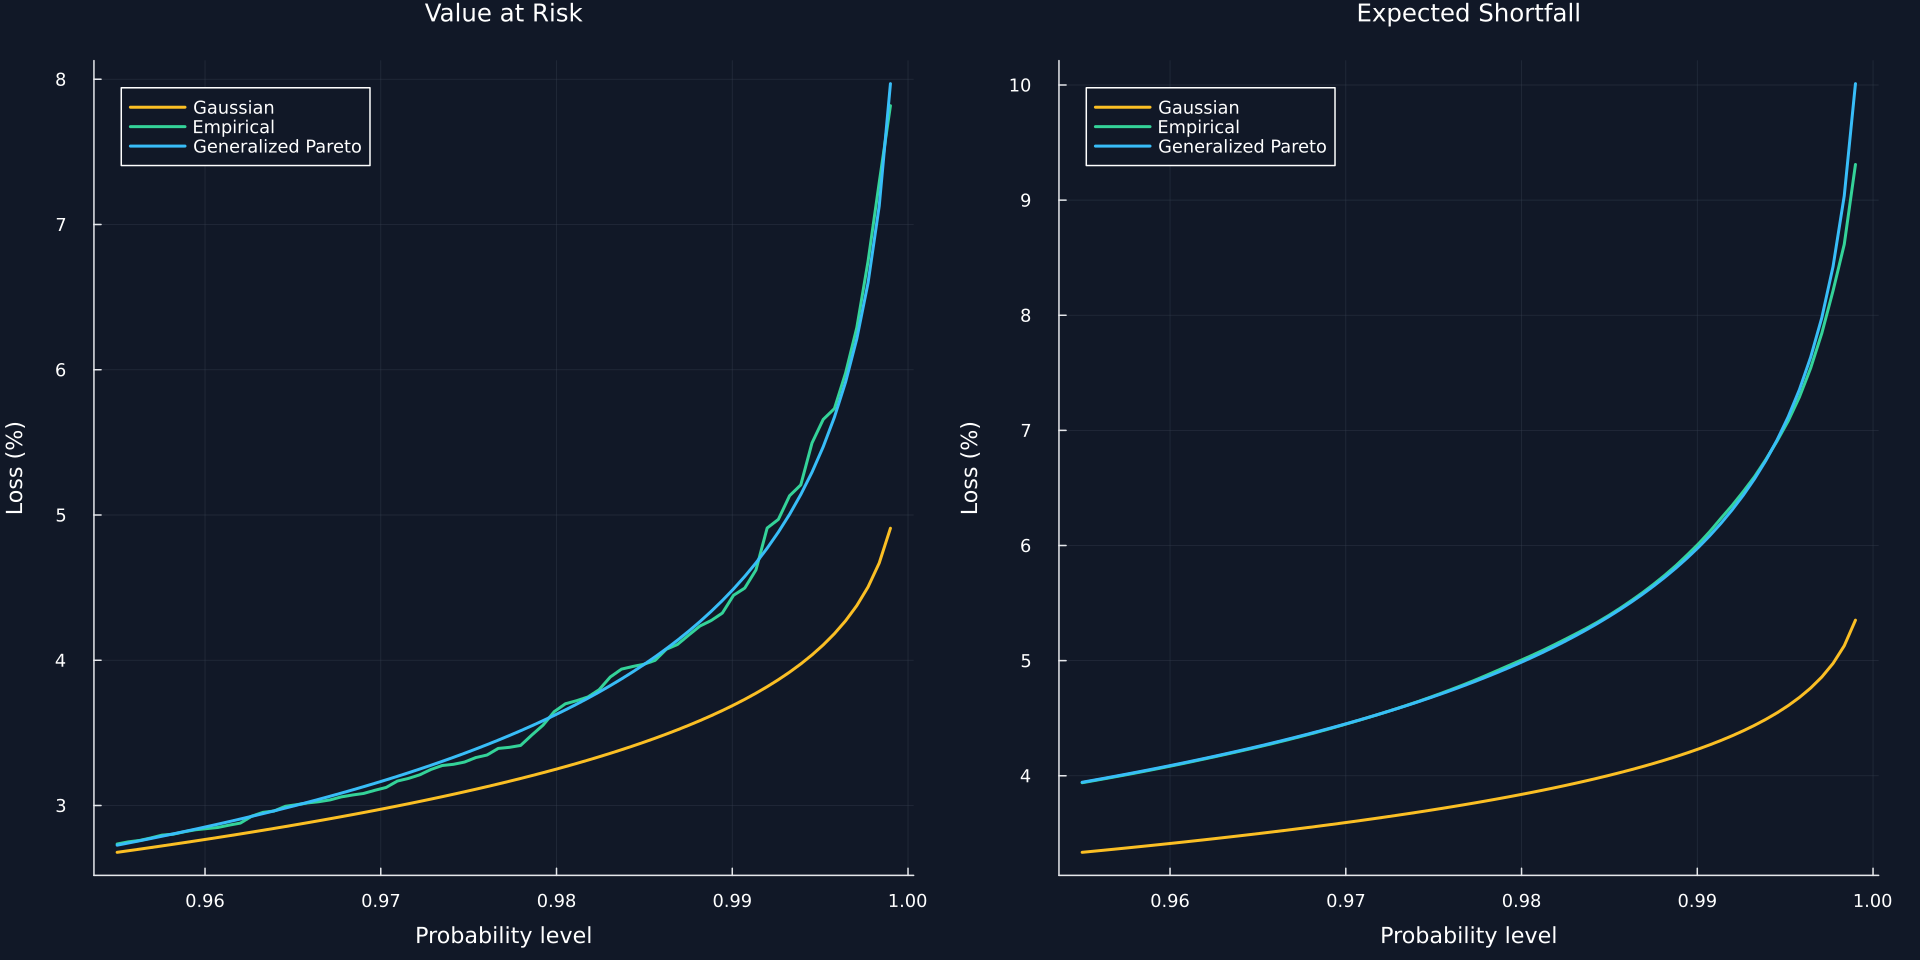

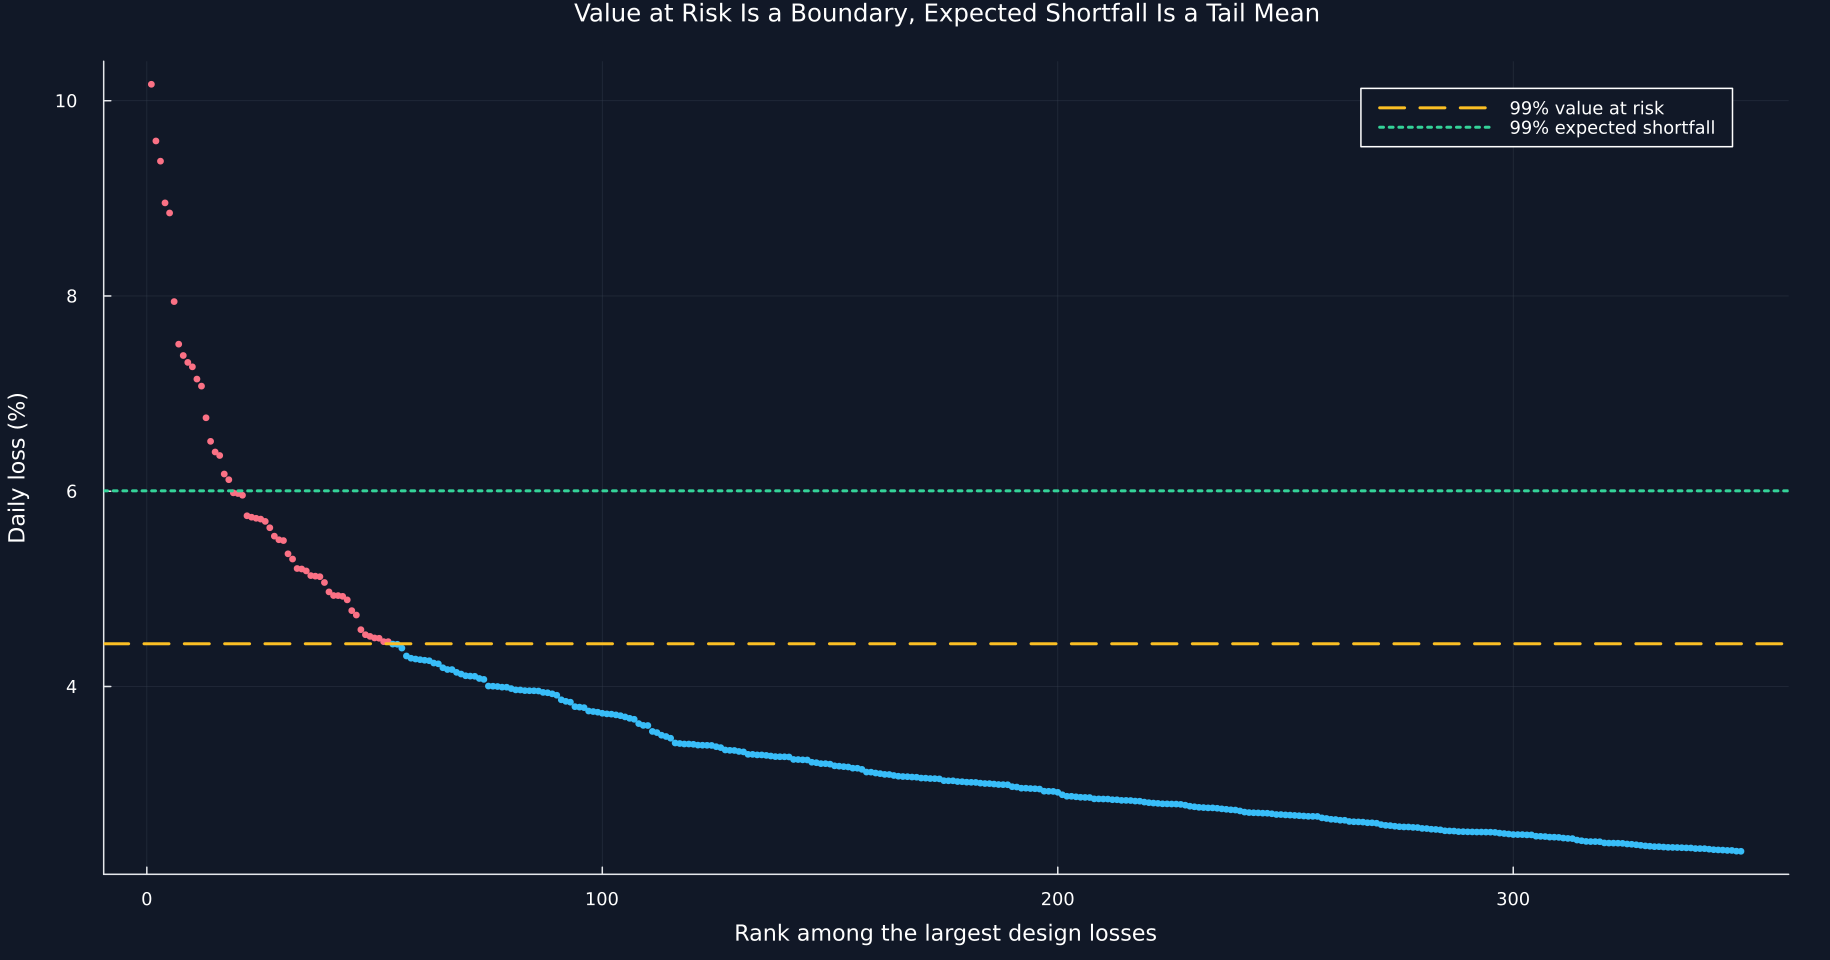

Row,Shape,99% VaR (%),99% ES (%),Finite expected shortfall
,Float64,Float64,Float64,Bool
1,-0.25,3.98888,4.54284,true
2,0.0,4.28439,5.32047,true
3,0.25,4.67102,6.73803,true
4,0.75,5.86053,19.7434,true
5,1.0,6.77139,Inf,false
6,1.25,8.00173,Inf,false


Row,Measure,Question,Needs
,String,String,String
1,Value at risk,What loss threshold has the stated upper-tail probability?,Probability level
2,Expected shortfall,What is the average loss in the stated upper tail?,Probability level
3,Maximum drawdown,What is the largest peak-to-trough fall on a path?,Path
4,Conditional expected drawdown,What is the mean of the worst horizon drawdowns?,Horizon and tail level


In [1]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"1.1.0"
configure_plots!()
paths = output_paths("21_tail_risk");
using CSV, TOML, Printf
using Distributions: Normal,quantile,pdf
using RiskLabAI.Backtest: expected_shortfall,conditional_expected_drawdown,generalized_pareto_tail_risk,quantile_exception_tests
include(joinpath("..","support","BookTailFit.jl"))
using .BookTailFit
source_path = dataset_path("fred_nasdaq")
@assert isfile(source_path)
raw = CSV.read(source_path,DataFrame;missingstring=["","."])
dropmissing!(raw,:NASDAQCOM)
sort!(raw,:observation_date)
price_dates,prices = Date.(raw.observation_date),Float64.(raw.NASDAQCOM)
log_returns = 100 .*log.(prices[2:end]./prices[1:end-1])
losses = -log_returns
simple_returns = expm1.(log_returns./100)
dates = price_dates[2:end]
design = findall(dates.<=Date(2014,12,31))
held = findall(dates.>=Date(2015,1,1))
design_losses,held_losses = losses[design],losses[held]
@assert length(design)==5287
@assert length(held)==2767
@assert last(dates[design])<first(dates[held])
@assert length(design)+length(held)==length(losses)
violet = "#C084FC"
table(frame,name,caption) = save_table(frame,paths,name;caption,label="tab:chapter21-"*replace(name,"_"=>"-"))
date_ticks(values;step=5) = let ticks=filter(date->first(values)<=date<=last(values),Date.(collect(year(first(values)):step:year(last(values))),1,1)); (Dates.value.(ticks),string.(year.(ticks))) end
save_data(DataFrame(date=dates,price=prices[2:end],log_return=log_returns,loss=losses,simple_return=simple_returns),paths,"drawdown_observations")

function empirical_tail(values,probability)
    ordered = sort(values)
    count = (1-probability)*length(values)
    complete = floor(Int,count)
    total = complete>0 ? sum(ordered[end-complete+1:end]) : 0.
    fraction = count-complete
    fraction>0 && (total += fraction*ordered[end-complete])
    return total/count
end

function path_drawdown(values)
    wealth = cumprod(1 .+ values)
    return 1 .- wealth./accumulate(max,wealth)
end

function rolling_drawdowns(values,horizon)
    wealth = cumprod(1 .+ values)
    length(wealth)<horizon && return [maximum(path_drawdown(values))]
    return [maximum(1 .- current./accumulate(max,current)) for current in (view(wealth,start:start+horizon-1) for start in 1:length(wealth)-horizon+1)]
end

function annual_forecast(probability)
    forecast = zeros(length(held))
    records = NamedTuple[]
    for forecast_year in sort(unique(year.(dates[held])))
        history = findall(dates.<Date(forecast_year,1,1))
        threshold = quantile(losses[history],.95)
        fit = fit_public_pot(losses[history];threshold,probability)
        forecast[year.(dates[held]).==forecast_year] .= fit.value_at_risk
        push!(records,(year=forecast_year,through=last(dates[history]),observations=length(history),threshold=threshold,excesses=fit.exceedance_count,shape=fit.shape,scale=fit.scale,var=fit.value_at_risk,es=fit.expected_shortfall))
    end
    frame = DataFrame(records)
    rename!(frame,["Forecast year","History through","History observations","Threshold (%)","Excesses","Shape","Scale (%)","Forecast VaR (%)","Forecast ES (%)"])
    @assert all(year.(frame[!,"History through"]).<frame[!,"Forecast year"])
    @assert all(isfinite,forecast)
    return forecast,frame
end

function forecasts_at(probability)
    threshold = quantile(design_losses,.95)
    fit = fit_public_pot(design_losses;threshold,probability)
    annual,records = annual_forecast(probability)
    forecasts = [fill(mean(design_losses)+std(design_losses)*quantile(Normal(),probability),length(held)),fill(quantile(design_losses,probability),length(held)),fill(fit.value_at_risk,length(held)),annual]
    return forecasts,records
end

forecast_names = ["Gaussian","Empirical","Generalized Pareto","Annual generalized Pareto"]
forecast_colors = [palette.amber,palette.green,palette.cyan,violet]
threshold = quantile(design_losses,.95)
pot = fit_public_pot(design_losses;threshold,probability=.99)
mu,sigma = mean(design_losses),std(design_losses)
risk_rows = NamedTuple[]
for probability in [.95,.975,.99,.995]
    z = quantile(Normal(),probability)
    push!(risk_rows,(probability=probability,tail=1-probability,method="Gaussian",var=mu+sigma*z,es=mu+sigma*pdf(Normal(),z)/(1-probability)))
    push!(risk_rows,(probability=probability,tail=1-probability,method="Empirical",var=quantile(design_losses,probability),es=-expected_shortfall(log_returns[design],0.;confidence_level=1-probability)))
    if probability>.95
        risk = generalized_pareto_tail_risk(threshold,pot.exceedance_probability,pot.shape,pot.scale,probability)
        push!(risk_rows,(probability=probability,tail=1-probability,method="Generalized Pareto",var=risk.value_at_risk,es=risk.expected_shortfall))
    end
end
risk_table = DataFrame(risk_rows)
rename!(risk_table,["Probability level","Tail probability","Method","VaR (%)","ES (%)"])
table(risk_table,"var_es_comparison","Design-sample value at risk and expected shortfall estimates.")
curve_rows = NamedTuple[]
for probability in range(.955,.999;length=70)
    z = quantile(Normal(),probability)
    push!(curve_rows,(probability=probability,method="Gaussian",var=mu+sigma*z,es=mu+sigma*pdf(Normal(),z)/(1-probability)))
    push!(curve_rows,(probability=probability,method="Empirical",var=quantile(design_losses,probability),es=empirical_tail(design_losses,probability)))
    risk = generalized_pareto_tail_risk(threshold,pot.exceedance_probability,pot.shape,pot.scale,probability)
    push!(curve_rows,(probability=probability,method="Generalized Pareto",var=risk.value_at_risk,es=risk.expected_shortfall))
end
curve = DataFrame(curve_rows)
rename!(curve,["Probability level","Method","VaR (%)","ES (%)"])
save_data(curve,paths,"var_expected_shortfall_curves")
p1 = plot(;title="Value at Risk",xlabel="Probability level",ylabel="Loss (%)",legend=:topleft)
p2 = plot(;title="Expected Shortfall",xlabel="Probability level",ylabel="Loss (%)",legend=:topleft)
for (method,color) in zip(forecast_names[1:3],forecast_colors[1:3])
    rows = curve.Method.==method
    plot!(p1,curve[rows,"Probability level"],curve[rows,"VaR (%)"];color,label=method)
    plot!(p2,curve[rows,"Probability level"],curve[rows,"ES (%)"];color,label=method)
end
save_figure(plot(p1,p2;layout=(1,2),size=(1280,640)),paths,"var_expected_shortfall_curves")
empirical_var,empirical_es = quantile(design_losses,.99),empirical_tail(design_losses,.99)
ordered = sort(design_losses;rev=true)[1:350]
contributions = DataFrame("Worst-loss rank"=>collect(1:350),"Loss (%)"=>ordered,"At or above 99% VaR"=>ordered.>=empirical_var,"99% VaR (%)"=>fill(empirical_var,350),"99% ES (%)"=>fill(empirical_es,350))
save_data(contributions,paths,"tail_loss_contributions")
figure = scatter(1:350,ordered;color=ifelse.(ordered.>=empirical_var,palette.rose,palette.cyan),markersize=2.5,markerstrokewidth=0,label="",xlabel="Rank among the largest design losses",ylabel="Daily loss (%)",title="Value at Risk Is a Boundary, Expected Shortfall Is a Tail Mean",legend=:topright,size=(1220,640))
hline!(figure,[empirical_var];color=palette.amber,linestyle=:dash,label="99% value at risk")
hline!(figure,[empirical_es];color=palette.green,linestyle=:dot,label="99% expected shortfall")
save_figure(figure,paths,"tail_loss_contributions")
boundary = DataFrame([(shape=shape,var=result.value_at_risk,es=result.expected_shortfall,finite=isfinite(result.expected_shortfall)) for shape in [-.25,0.,.25,.75,1.,1.25] for result in [generalized_pareto_tail_risk(threshold,pot.exceedance_probability,shape,pot.scale,.99)]])
rename!(boundary,["Shape","99% VaR (%)","99% ES (%)","Finite expected shortfall"])
table(boundary,"finite_mean_boundary","The generalized Pareto finite-mean boundary.")
@assert isapprox(empirical_es,-expected_shortfall(log_returns[design],0.;confidence_level=.01);atol=.02)
@assert all(risk_table[!,"ES (%)"].>=risk_table[!,"VaR (%)"])
@assert !any(boundary[boundary.Shape.>=1,"Finite expected shortfall"])
definitions = DataFrame("Measure"=>["Value at risk", "Expected shortfall", "Maximum drawdown", "Conditional expected drawdown"],"Question"=>["What loss threshold has the stated upper-tail probability?", "What is the average loss in the stated upper tail?", "What is the largest peak-to-trough fall on a path?", "What is the mean of the worst horizon drawdowns?"],"Needs"=>["Probability level", "Probability level", "Path", "Horizon and tail level"])
table(definitions,"risk_measure_definitions","Risk measure definitions.")


## Drawdown as a Path Quantity

For wealth \(W_t\), drawdown at date \(t\) is

$$
D_t=1-\frac{W_t}{\max_{s\leq t}W_s},
$$

where the denominator is the highest wealth reached through date \(t\). Maximum drawdown over a path is \(\max_t D_t\). For a fixed horizon \(h\), let \(M_h\) denote maximum drawdown within a horizon window. Conditional expected drawdown at level \(a\) is

$$
\operatorname{CED}_{a,h}=\frac{1}{1-a}\int_a^1\operatorname{VaR}_q(M_h)\,dq.
$$

The horizon \(h\) is measured in trading days, \(a\) is the covered probability, and \(M_h\) is a distribution of path losses rather than one-day losses. The reported value must therefore state both the horizon and the tail level.

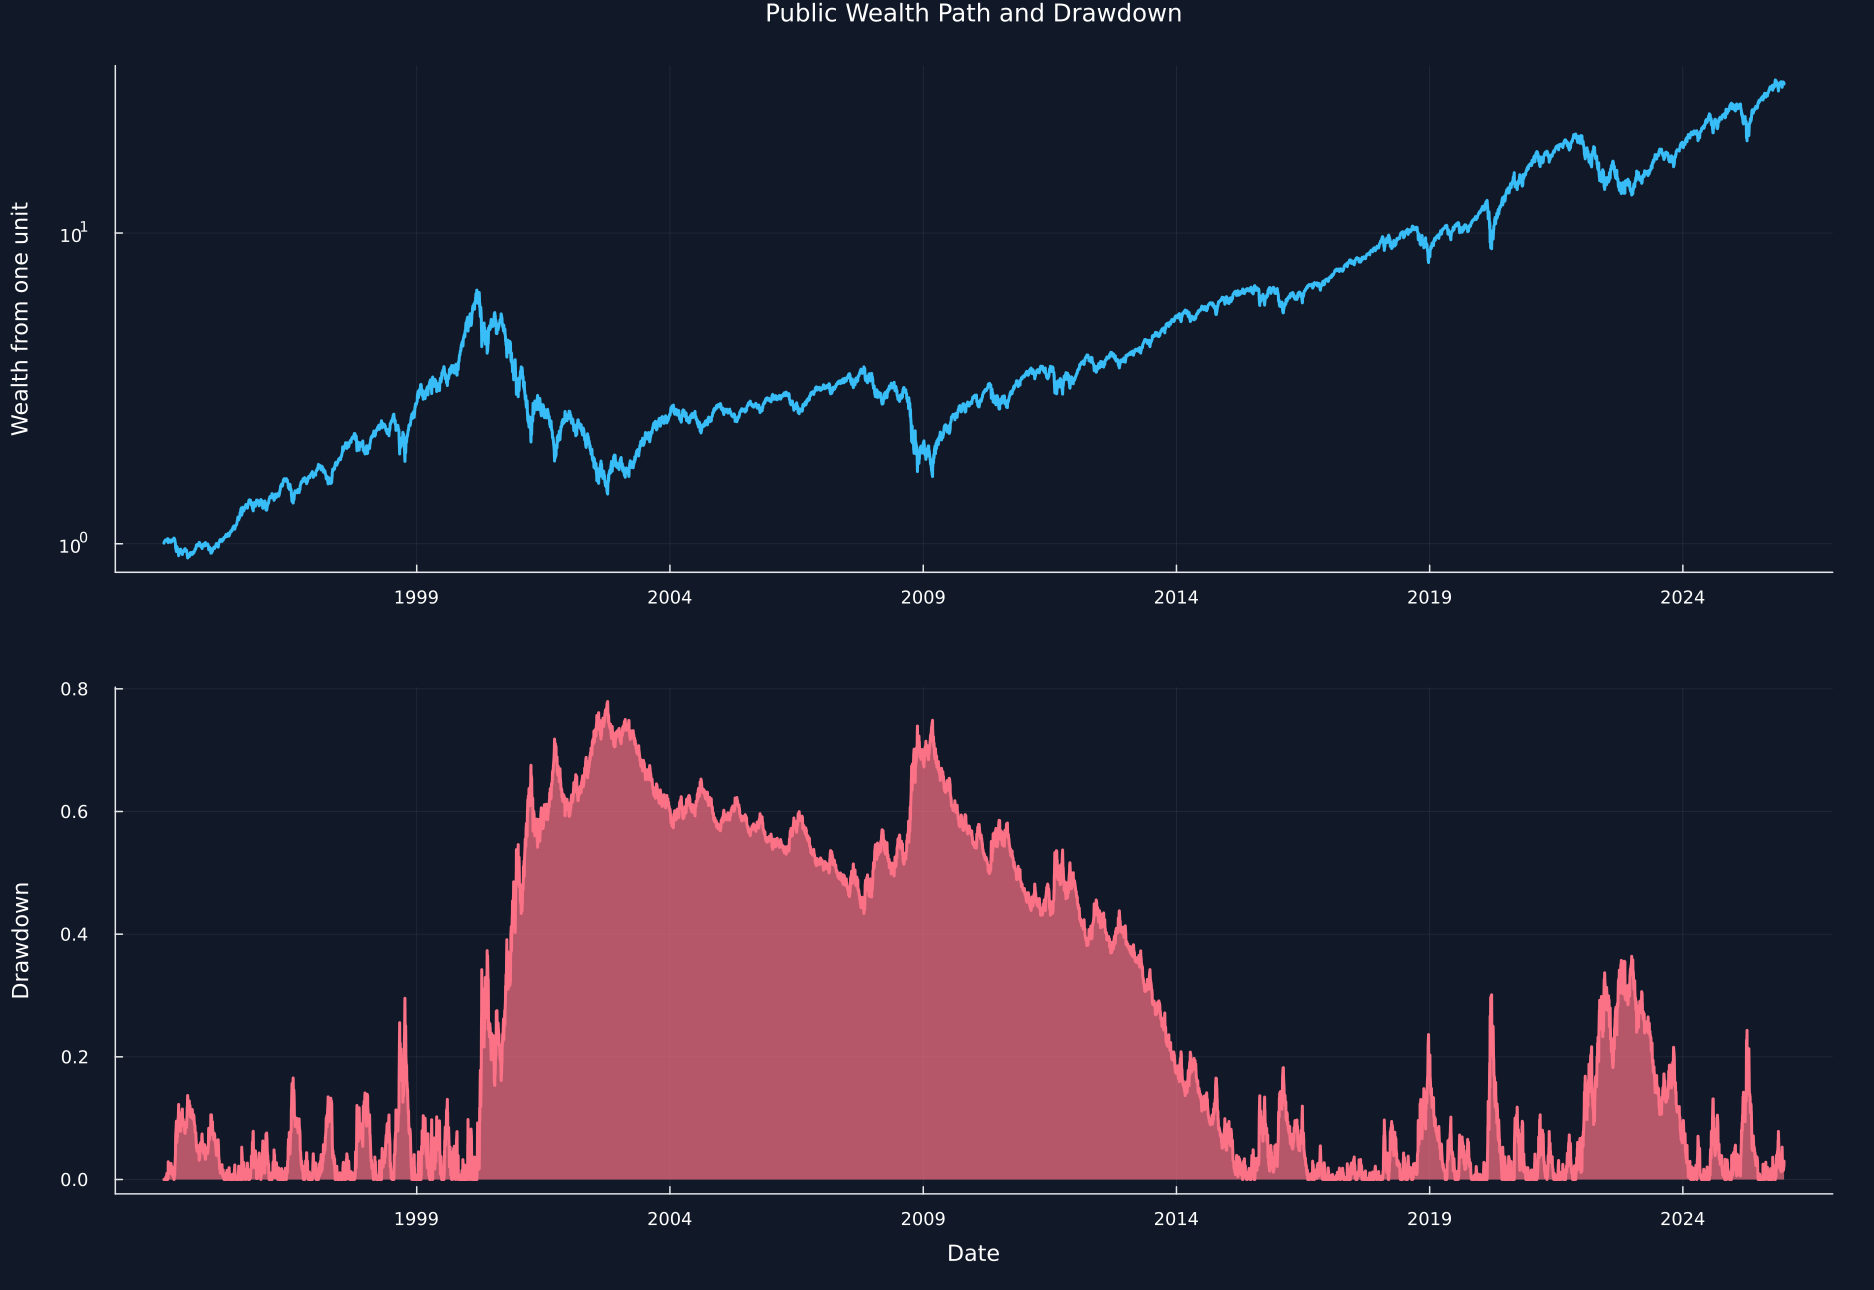

Row,Horizon in trading days,Tail level,Rolling windows,Conditional expected drawdown,Largest window drawdown
,Int64,Float64,Int64,Float64,Float64
1,20,0.9,8035,0.155845,0.330794
2,20,0.95,8035,0.189706,0.330794
3,20,0.975,8035,0.223604,0.330794
4,60,0.9,7995,0.276772,0.454263
5,60,0.95,7995,0.329062,0.454263
6,60,0.975,7995,0.365959,0.454263
7,126,0.9,7929,0.383088,0.534841
8,126,0.95,7929,0.434595,0.534841
9,126,0.975,7929,0.475784,0.534841


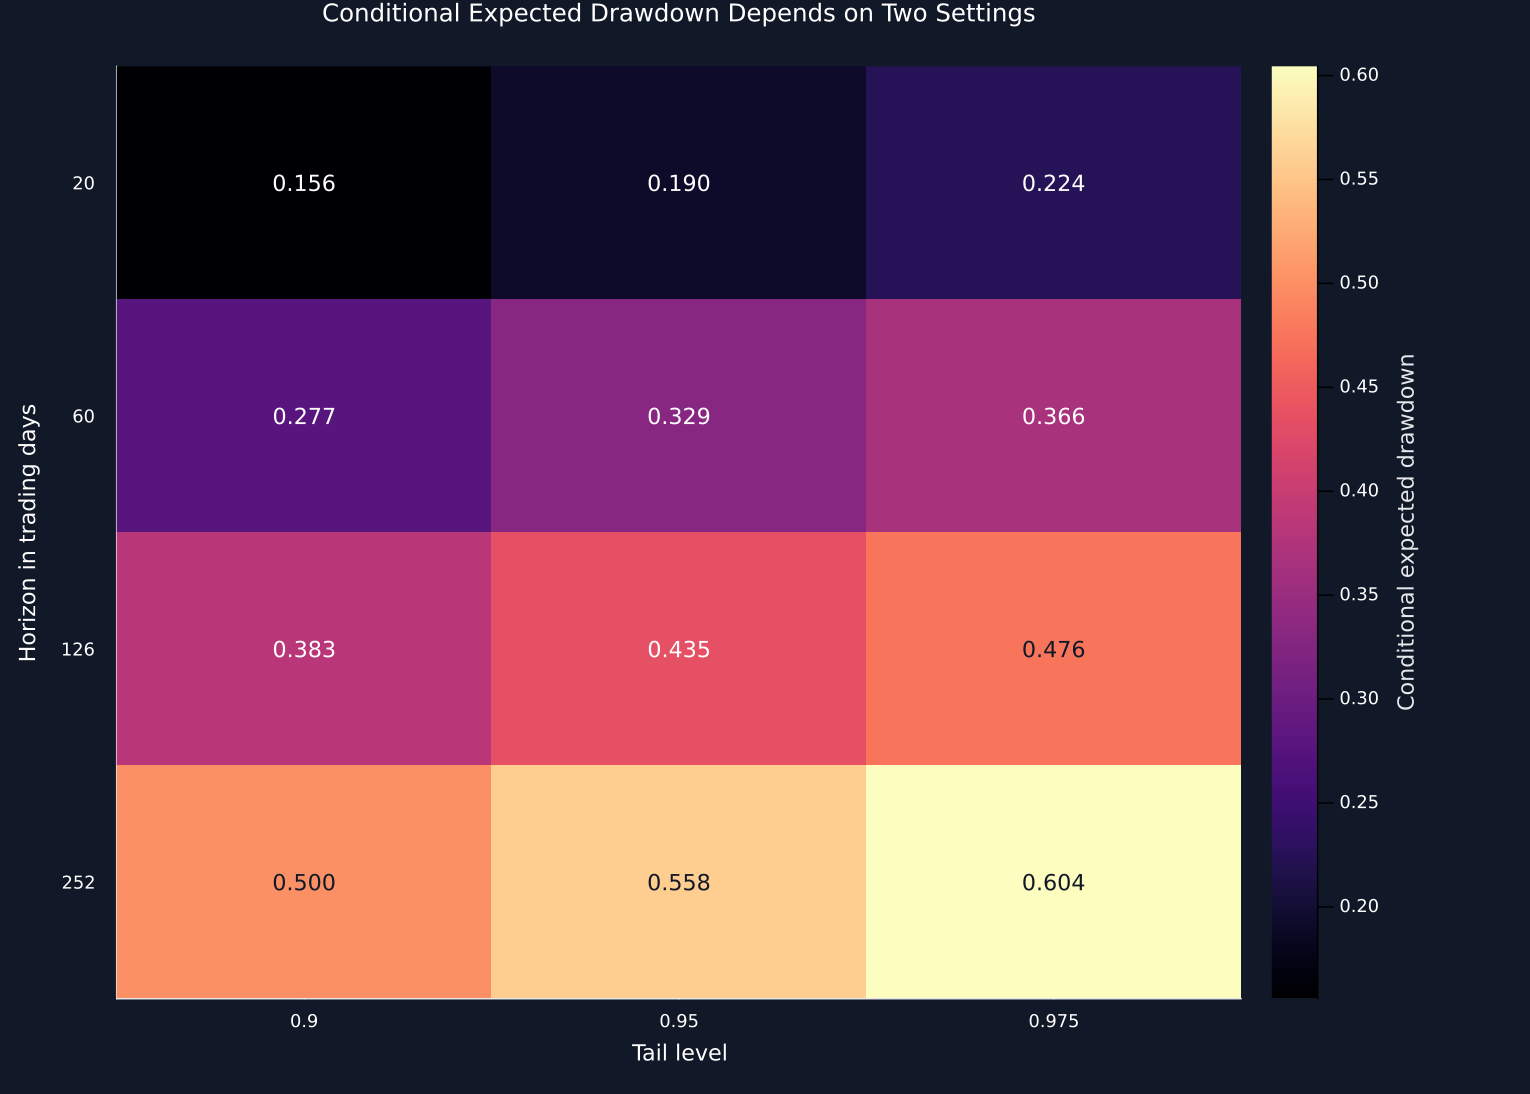

Row,Quantity,Construction,Unit
,String,String,String
1,Wealth,Cumulative product of one plus each simple return,Relative wealth
2,Drawdown,One minus wealth divided by its running maximum,Fraction
3,Maximum drawdown,Largest drawdown on a path or window,Fraction
4,Conditional expected drawdown,Upper-tail mean of horizon maximum drawdowns,Fraction


In [2]:
wealth = cumprod(1 .+ simple_returns)
drawdown = 1 .- wealth./accumulate(max,wealth)
drawdown_history = DataFrame("Date"=>dates,"Wealth from one unit"=>wealth,"Drawdown"=>drawdown)
save_data(drawdown_history,paths,"wealth_drawdown_history")
p1 = plot(Dates.value.(dates),wealth;yscale=:log10,xticks=date_ticks(dates),color=palette.cyan,label="",ylabel="Wealth from one unit",title="Public Wealth Path and Drawdown")
p2 = plot(Dates.value.(dates),drawdown;fillrange=0,fillalpha=.7,xticks=date_ticks(dates),color=palette.rose,label="",xlabel="Date",ylabel="Drawdown")
save_figure(plot(p1,p2;layout=(2,1),size=(1250,860)),paths,"wealth_drawdown_history")
drawdown_rows = NamedTuple[]
for horizon in [20,60,126,252]
    maxima = rolling_drawdowns(simple_returns,horizon)
    save_data(DataFrame(window=collect(eachindex(maxima)),maximum_drawdown=maxima),paths,"rolling_drawdowns_"*string(horizon))
    for level in [.90,.95,.975]
        result = conditional_expected_drawdown(simple_returns,horizon,level)
        push!(drawdown_rows,(horizon=horizon,level=level,windows=length(maxima),ced=result,largest=maximum(maxima)))
    end
end
drawdown_sensitivity = DataFrame(drawdown_rows)
rename!(drawdown_sensitivity,["Horizon in trading days","Tail level","Rolling windows","Conditional expected drawdown","Largest window drawdown"])
table(drawdown_sensitivity,"drawdown_sensitivity","Conditional expected drawdown across horizons and tail levels.")
heat = select(drawdown_sensitivity,["Horizon in trading days","Tail level","Conditional expected drawdown"])
save_data(heat,paths,"drawdown_sensitivity_heatmap")
matrix = permutedims(reshape(heat[!,"Conditional expected drawdown"],3,4))
figure = heatmap(1:3,1:4,matrix;xticks=(1:3,["0.9","0.95","0.975"]),yticks=(1:4,["20","60","126","252"]),yflip=true,color=:magma,xlabel="Tail level",ylabel="Horizon in trading days",title="Conditional Expected Drawdown Depends on Two Settings",colorbar_title="Conditional expected drawdown",grid=false,right_margin=17Plots.mm,size=(1020,730))
for row in 1:4,column in 1:3
    annotate!(figure,column,row,text(@sprintf("%.3f",matrix[row,column]),10,matrix[row,column]>.45 ? "#111827" : "#FFFFFF"))
end
save_figure(figure,paths,"drawdown_sensitivity_heatmap")
@assert all(drawdown.>=0)
@assert all(drawdown.<1)
@assert all(drawdown_sensitivity[!,"Conditional expected drawdown"].<=drawdown_sensitivity[!,"Largest window drawdown"].+1e-12)
drawdown_definitions = DataFrame("Quantity"=>["Wealth", "Drawdown", "Maximum drawdown", "Conditional expected drawdown"],"Construction"=>["Cumulative product of one plus each simple return", "One minus wealth divided by its running maximum", "Largest drawdown on a path or window", "Upper-tail mean of horizon maximum drawdowns"],"Unit"=>["Relative wealth", "Fraction", "Fraction", "Fraction"])
table(drawdown_definitions,"drawdown_definitions","Drawdown definitions.")


## Public-Data Block Resampling

A moving-block resample joins blocks of \(b\) consecutive design returns until a path of length \(m\) is filled:

$$
R^{*(j)}=\bigl(R_{S_1:S_1+b-1},R_{S_2:S_2+b-1},\ldots\bigr)_{1:m}.
$$

Here, \(S_1,S_2,\ldots\) are independently drawn block starting positions, \(b=20\) is the block length, \(m=500\) is the resampled path length, and \(j\) identifies one of 300 resamples. Blocks preserve short runs from the public design sample. They do not create new market observations or a population truth.

For a positive statistic \(X\), its coefficient of variation is

$$
\operatorname{CV}(X)=\frac{\operatorname{sd}(X)}{\mathbb{E}[X]}.
$$

The standard deviation measures dispersion across resamples and the mean rescales it. This experiment compares the sampling variation of maximum drawdown and conditional expected drawdown only under the declared public-data resampling design.

Row,Setting,Value
,String,Float64
1,Resamples,300.0
2,Path length,500.0
3,Block length,20.0
4,Drawdown horizon,60.0
5,CED tail level,0.95
6,Random seed,2202.0


Row,Measure,Mean,Standard deviation,Coefficient of variation,Minimum,Maximum
,String,Float64,Float64,Float64,Float64,Float64
1,Maximum drawdown,0.297579,0.111121,0.373417,0.0893565,0.707522
2,Conditional expected drawdown,0.238913,0.0722601,0.302453,0.0891873,0.434212


Row,Measure,Probability,Quantile
,String,Float64,Float64
1,Maximum drawdown,0.05,0.141433
2,Maximum drawdown,0.25,0.210862
3,Maximum drawdown,0.5,0.283787
4,Maximum drawdown,0.75,0.373498
5,Maximum drawdown,0.95,0.485313
6,Conditional expected drawdown,0.05,0.132264
7,Conditional expected drawdown,0.25,0.188119
8,Conditional expected drawdown,0.5,0.23103
9,Conditional expected drawdown,0.75,0.284972


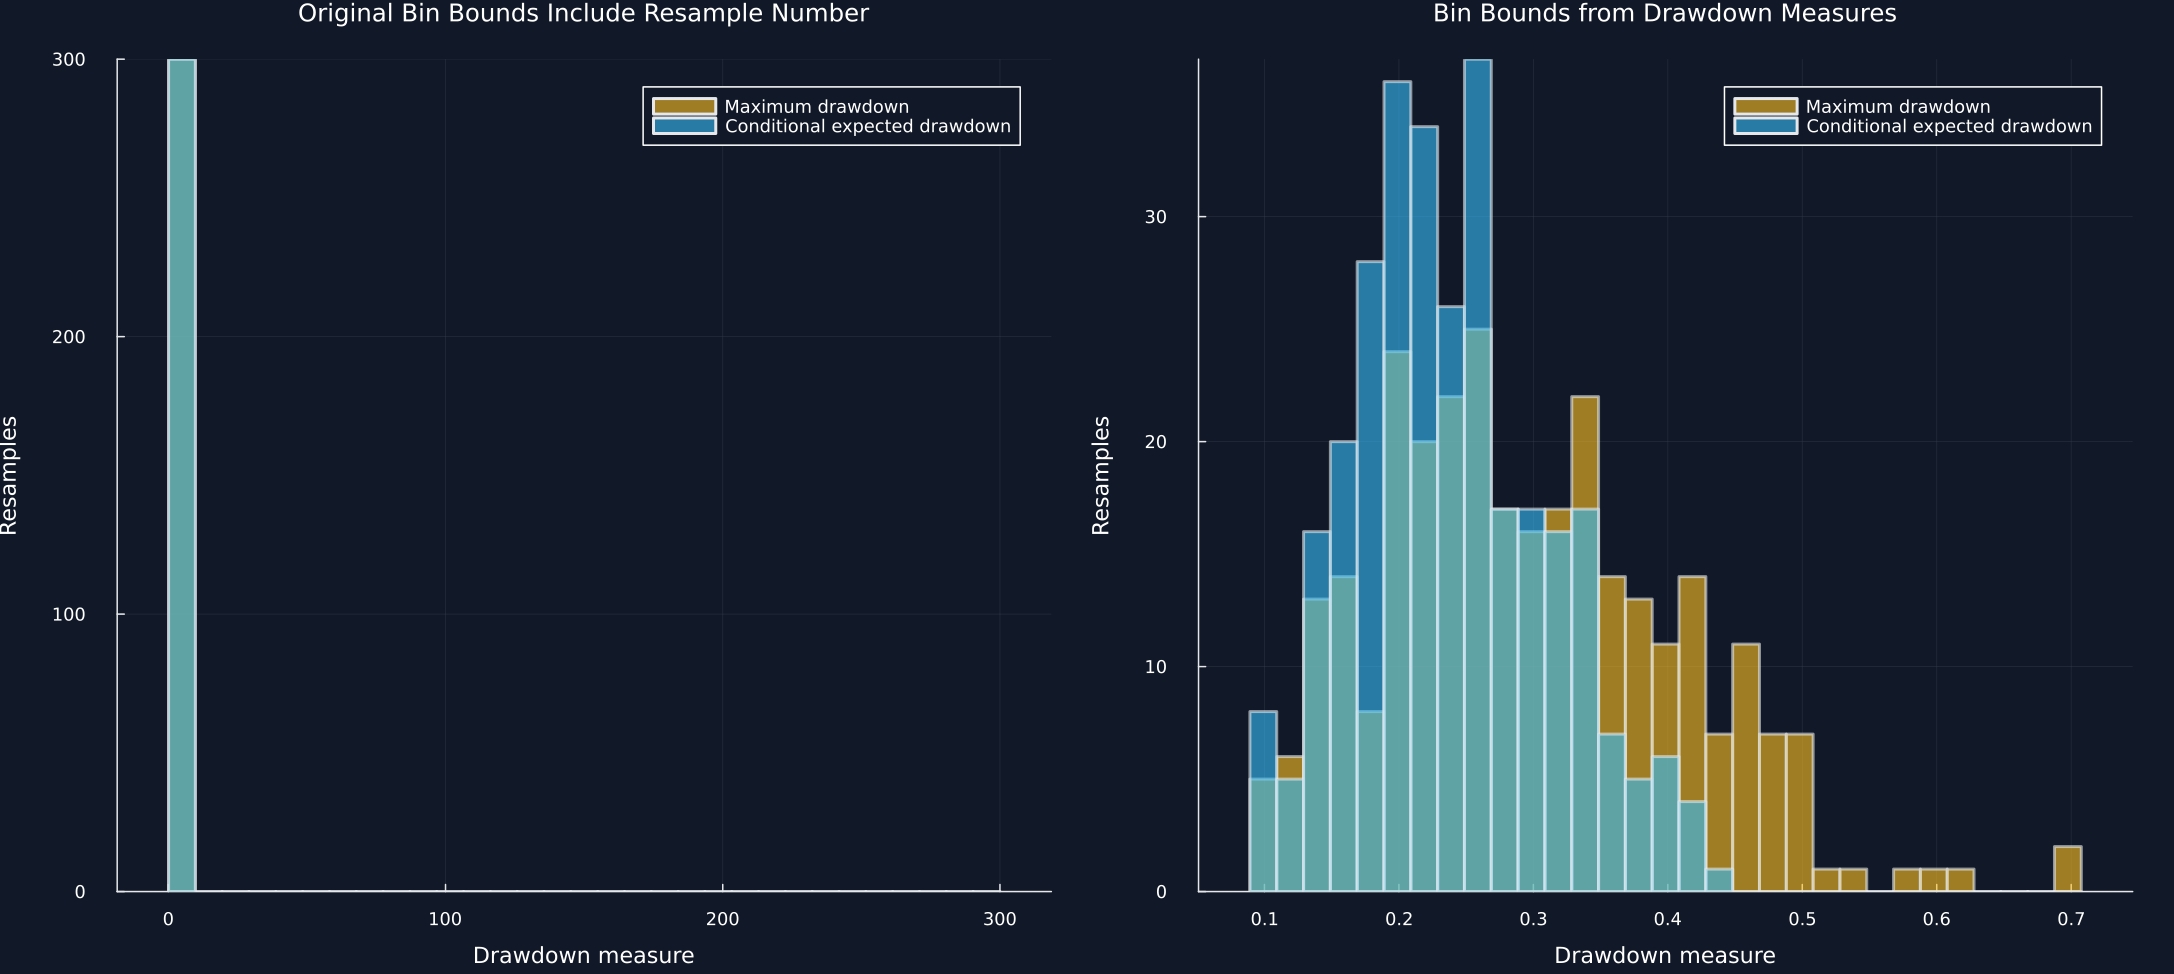

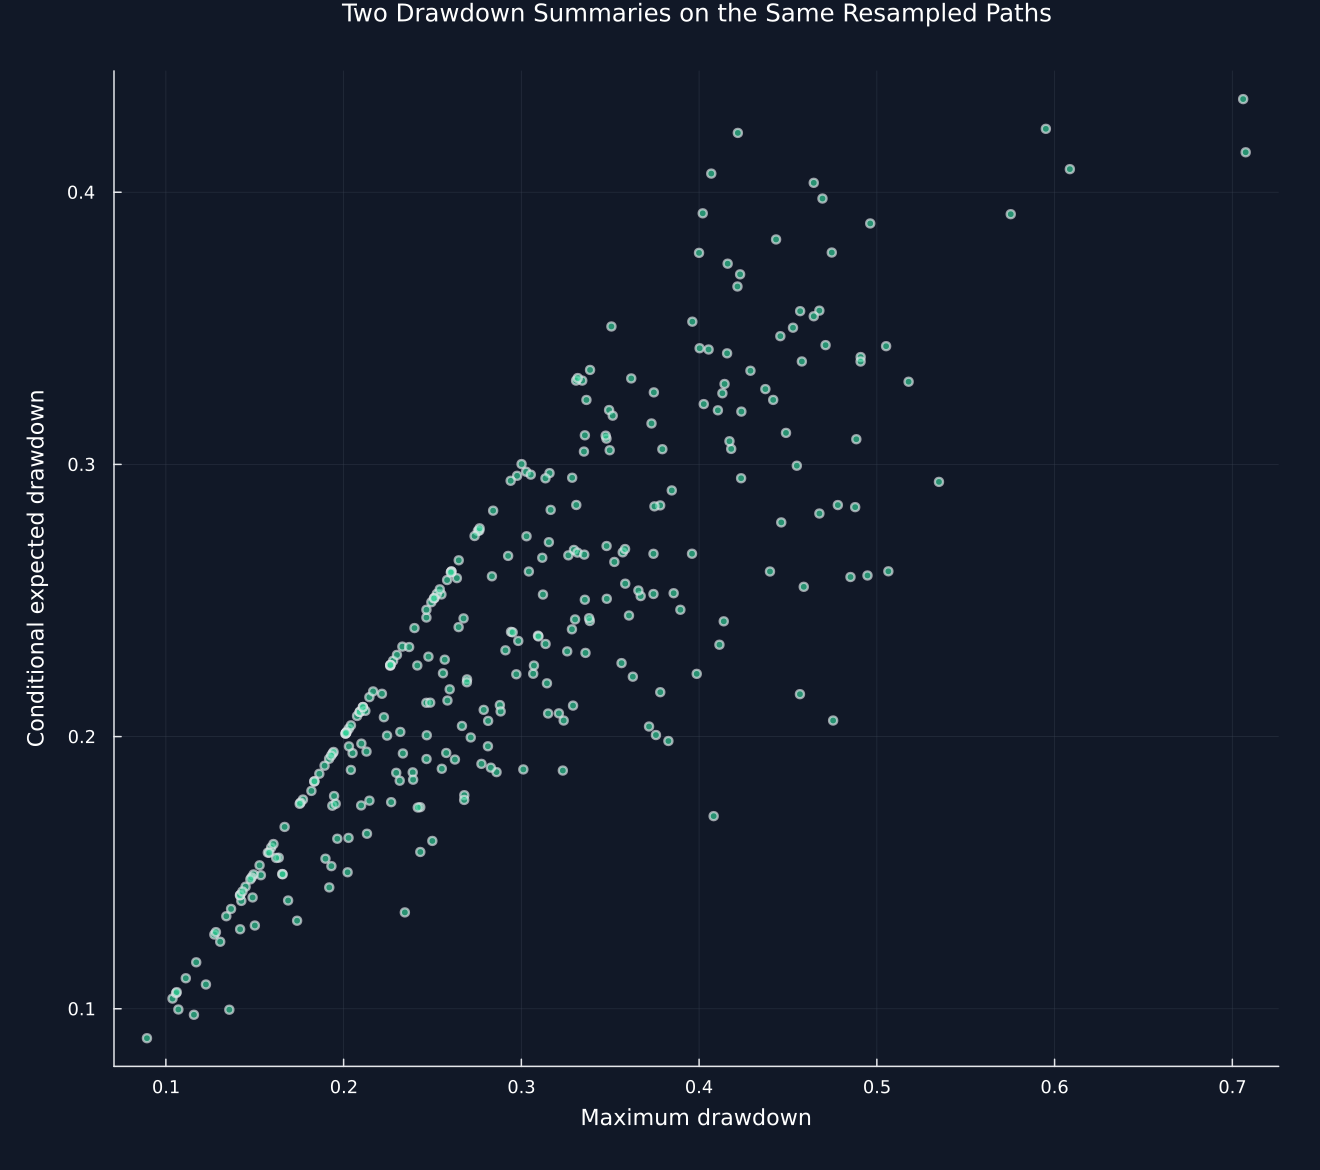

Row,Check,Result
,String,Bool
1,Only design-sample returns were resampled,true
2,Requested number of resamples,true
3,"All maximum drawdowns lie in [0,1)",true
4,"All conditional expected drawdowns lie in [0,1)",true
5,Conditional expected drawdown does not exceed path maximum drawdown,true


In [3]:
primitive_root = joinpath("..","data","chapter21_random_inputs")
primitive_manifest = joinpath(primitive_root,"inputs.toml")
metadata = TOML.parsefile(primitive_manifest)["files"]["drawdown_bootstrap.csv"]
primitive_path = joinpath(primitive_root,"drawdown_bootstrap.csv")
positions = Matrix{Int}(CSV.read(primitive_path,DataFrame))
@assert size(positions)==(500,300)
@assert all(1 .<= positions .<= length(design))
design_returns = simple_returns[design]
resampled = DataFrame("Resample"=>collect(1:300),"Maximum drawdown"=>[maximum(path_drawdown(design_returns[rows])) for rows in eachcol(positions)],"Conditional expected drawdown"=>[conditional_expected_drawdown(design_returns[rows],60,.95) for rows in eachcol(positions)])
save_data(resampled,paths,"resampled_drawdown_measures")
settings_table = DataFrame("Setting"=>["Resamples","Path length","Block length","Drawdown horizon","CED tail level","Random seed"],"Value"=>[300,500,20,60,.95,2202])
table(settings_table,"resampling_settings","Fixed public-data resampling settings.")
measure_names = ["Maximum drawdown","Conditional expected drawdown"]
resampling_summary = DataFrame([(measure=name,average=mean(values),deviation=std(values),cv=std(values)/mean(values),minimum=minimum(values),maximum=maximum(values)) for name in measure_names for values in [resampled[!,name]]])
rename!(resampling_summary,["Measure","Mean","Standard deviation","Coefficient of variation","Minimum","Maximum"])
table(resampling_summary,"resampling_summary","Sampling variation under the fixed block-resampling design.")
resampling_quantiles = DataFrame([(measure=name,probability=probability,quantile=quantile(resampled[!,name],probability)) for name in measure_names for probability in [.05,.25,.50,.75,.95]])
rename!(resampling_quantiles,["Measure","Probability","Quantile"])
table(resampling_quantiles,"resampling_quantiles","Quantiles across public-data block resamples.")
function histogram_counts(values,edges)
    counts = zeros(Int,length(edges)-1)
    for value in values
        position = clamp(searchsortedlast(edges,value),1,length(counts))
        counts[position] += 1
    end
    return counts
end
original_bins = collect(range(minimum(Matrix(resampled)),maximum(Matrix(resampled));length=32))
measure_values = Matrix(select(resampled,measure_names))
measure_bins = collect(range(minimum(measure_values),maximum(measure_values);length=32))
panels = []
for (name,edges,title) in [("original",original_bins,"Original Bin Bounds Include Resample Number"),("measures",measure_bins,"Bin Bounds from Drawdown Measures")]
    histogram_data = DataFrame(lower=edges[1:end-1],upper=edges[2:end],maximum_drawdown=histogram_counts(resampled[!,measure_names[1]],edges),conditional_drawdown=histogram_counts(resampled[!,measure_names[2]],edges))
    save_data(histogram_data,paths,"resampled_histogram_"*name)
    figure = plot(;xlabel="Drawdown measure",ylabel="Resamples",title,legend=:topright)
    for (column,color,label) in [("maximum_drawdown",palette.amber,"Maximum drawdown"),("conditional_drawdown",palette.cyan,"Conditional expected drawdown")]
        bar!(figure,(edges[1:end-1].+edges[2:end])./2,histogram_data[!,column];bar_width=diff(edges),color,alpha=.6,label)
    end
    push!(panels,figure)
end
save_figure(plot(panels...;layout=(1,2),size=(1450,650)),paths,"resampled_drawdown_distributions")
figure = scatter(resampled[!,measure_names[1]],resampled[!,measure_names[2]];color=palette.green,alpha=.65,markersize=3,label="",xlabel="Maximum drawdown",ylabel="Conditional expected drawdown",title="Two Drawdown Summaries on the Same Resampled Paths",size=(880,780))
save_figure(figure,paths,"resampled_drawdown_scatter")
checks = DataFrame("Check"=>["Only design-sample returns were resampled","Requested number of resamples","All maximum drawdowns lie in [0,1)","All conditional expected drawdowns lie in [0,1)","Conditional expected drawdown does not exceed path maximum drawdown"],"Result"=>[length(design_returns)==5287,nrow(resampled)==300,all(0 .<=resampled[!,measure_names[1]].<1),all(0 .<=resampled[!,measure_names[2]].<1),all(resampled[!,measure_names[2]].<=resampled[!,measure_names[1]].+1e-12)])
table(checks,"resampling_checks","Checks for the public-data block resampling experiment.")
@assert all(checks.Result)
@assert all(isfinite,Matrix(resampling_summary[:,2:end]))
